# Modularity on the Karate Club Graph
**Course:** DSC212, Research Assignment on Graph Theory Module  
**Author:** Marwa Fathima M K / IMS25123

This notebook detects communities in Zachary's Karate Club network using **spectral modularity maximisation** (Newman, 2006), applied by **recursive bisection**. After every split it redraws the graph with one colour per community and records four node-level measures: degree, betweenness, closeness and clustering.

**Contents**

1. Imports
2. Graph, layout and the modularity matrix $\mathbf{B}$
3. Computing node metrics
4. Helper functions: modularity score and the plot after each split
5. Baseline (iteration 0)
6. The bisection loop
7. Preparing the metric-evolution plots
8. Evolution of the metrics
9. Top-5 nodes per metric and iteration
10. Discussion and notes

> **How to run:** *Kernel → Restart & Run All*. Everything runs top to bottom, and the Karate Club data ships with NetworkX, so nothing needs to be downloaded.

---
## 1. Imports

* `networkx` provides the graph and the centrality functions.
* `numpy` handles the matrices.
* `scipy.linalg.eigh` computes eigenvalues and eigenvectors of a real symmetric matrix. This is the right routine here because both $\mathbf{B}$ and the restricted blocks are symmetric, so the eigenvalues are real and the eigenvectors orthonormal.
* `matplotlib` draws all the figures.

In [1]:
import networkx as nx
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

---
## 2. Graph, layout and the modularity matrix

This cell builds everything the algorithm needs.

* **Graph and counts.** `G` is the Karate Club graph with $n=34$ nodes and $m=78$ edges. We store `twom` $=2m=156$ because it appears in every formula.
* **Fixed layout.** `pos` is computed **once** with a fixed seed. Every later plot reuses it, so nodes never move between iterations and only the colours change.
* **Adjacency matrix.** NetworkX's copy of this dataset carries an edge attribute `weight`. Passing `weight=None` makes `A` the plain **unweighted** 0/1 matrix, as the assignment requires.
* **Modularity matrix.**
$$B_{ij} = A_{ij} - \frac{k_i k_j}{2m}$$
Here $A_{ij}$ is the observed connection between $i$ and $j$, and $k_ik_j/2m$ is the number of edges expected between them in the degree-preserving random model. A positive $B_{ij}$ means $i$ and $j$ are more connected than chance predicts.
* **Communities.** `communities` starts as one group containing every node. Each iteration will replace it with a finer partition.
* **Colours.** Two lists give each community a name and a hex colour for the plots.

In [2]:
G = nx.karate_club_graph()
n = G.number_of_nodes()
m = G.number_of_edges()
twom = 2 * m

pos = nx.spring_layout(G, seed=42)

A = nx.to_numpy_array(G, weight=None)   # unweighted 0/1 matrix

B_global = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        B_global[i, j] = A[i, j] - (G.degree(i) * G.degree(j)) / twom

communities = [list(G.nodes())]

color_names = ["red", "blue", "green", "orange", "purple", "brown", "pink"]
color_hex = ["#e41a1c", "#377eb8", "#4daf4a", "#ff7f00", "#984ea3", "#a65628", "#f781bf"]

---
## 3. Node metrics: `compute_metrics`

After each split we compute four standard measures with NetworkX's built-in functions:

| Metric | Meaning | NetworkX call |
|---|---|---|
| Degree centrality | fraction of nodes a node is directly linked to | `nx.degree_centrality` |
| Betweenness centrality | how often a node lies on shortest paths between others (bridges and brokers) | `nx.betweenness_centrality` |
| Closeness centrality | inverse of the average distance to all other nodes | `nx.closeness_centrality` |
| Clustering coefficient | fraction of a node's neighbours that are also linked to each other | `nx.clustering` |

**Design choice.** Metrics on the *whole* graph would not change from split to split, so each metric is computed **inside the subgraph of the node's current community** (`G.subgraph(comm)`). Iteration 0 therefore gives the ordinary global values, and later iterations show how central each node is *within its own group*.

A community with a single node has nothing to connect to, so all four metrics are set to `0` for it.

Results are saved in `metrics_history[iteration][metric][node]`, which is what the evolution plots read later.

In [3]:
metrics_history = {}

def compute_metrics(iteration_num):
    """Compute the 4 centrality/cohesion metrics for every node,
    evaluated inside the subgraph of the node's current community."""
    deg, bet, clo, clu = {}, {}, {}, {}
    for comm in communities:
        if len(comm) == 1:
            node = comm[0]
            deg[node] = bet[node] = clo[node] = clu[node] = 0.0
            continue
        sub = G.subgraph(comm)
        deg.update(nx.degree_centrality(sub))
        bet.update(nx.betweenness_centrality(sub))
        clo.update(nx.closeness_centrality(sub))
        clu.update(nx.clustering(sub))
    metrics_history[iteration_num] = {
        "Degree centrality": deg,
        "Betweenness centrality": bet,
        "Closeness centrality": clo,
        "Clustering coefficient": clu,
    }

---
## 4. Helper functions: modularity score and the snapshot plot

**`calculate_exact_global_q`** computes the modularity of the current partition directly from its definition:
$$Q = \frac{1}{2m}\sum_{C}\sum_{i,j\in C} B_{ij}.$$
It adds up $B_{ij}$ over all pairs of nodes that share a community, so $Q$ is large when communities contain many more edges than chance would give them.

**`render_iteration_snapshot`** draws the graph on the fixed layout. Nodes take the colour of their community, are labelled with their ID, and the title shows the number of communities and $Q$. A side box lists which communities were split in this step and how large each group is. The same information is also printed as text.

In [4]:
def calculate_exact_global_q():
    q_sum = 0.0
    for comm in communities:
        for i in comm:
            for j in comm:
                q_sum += B_global[i, j]
    return q_sum / twom

def render_iteration_snapshot(iteration_num, log_text):
    plt.figure(figsize=(11.5, 6.5))

    node_colors = ["" for _ in range(n)]
    labels_summary = []

    for c_idx, comm in enumerate(communities):
        c_color = color_hex[c_idx % len(color_hex)]
        c_name = color_names[c_idx % len(color_names)]
        labels_summary.append(f"• Community {c_idx} ({c_name}, {len(comm)} nodes)")
        for node in comm:
            node_colors[node] = c_color

    q_val = calculate_exact_global_q()

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=450, edgecolors='black', alpha=0.9)
    nx.draw_networkx_edges(G, pos, width=0.8, alpha=0.4, edge_color='gray')
    nx.draw_networkx_labels(G, pos, font_size=8, font_color='white', font_weight='bold')

    plt.title(f"Iteration {iteration_num}: {len(communities)} communities (Q = {q_val:.4f})",
              fontsize=12, fontweight='bold', loc='center', pad=10)

    summary_text = f"Action Updates:\n{log_text}\n\nGroup Layout:\n" + "\n".join(labels_summary)
    plt.gcf().text(0.65, 0.35, summary_text, fontsize=9.5, linespacing=1.4,
                   bbox=dict(boxstyle="round,pad=0.5", facecolor="#f9f9f9", edgecolor="#dddddd"))

    print(f"########## Iteration {iteration_num} ##########")
    print(log_text)
    print(f"Modularity score Q = {q_val:.4f}\n")

    plt.axis('off')
    plt.subplots_adjust(right=0.6)
    plt.show()

---
## 5. Baseline: iteration 0

Before any splitting, all 34 nodes are in a single community. We store the baseline metrics (these equal the plain global NetworkX values) and draw the starting graph.

A single group is the trivial partition, so its modularity is exactly $0$. The printed `-0.0000` is only floating-point rounding of a value that is zero to numerical precision.

Launching Generalized Global Modularity Partitioning Engine...
########## Iteration 0 ##########
Initial baseline state: All 34 nodes unified inside a single group.
Modularity score Q = -0.0000


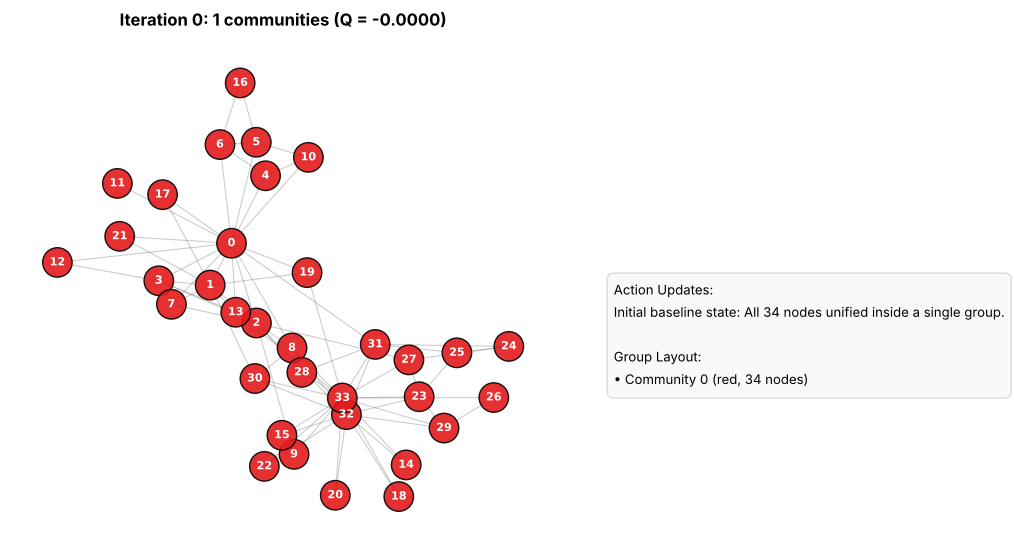

In [5]:
print("Launching Generalized Global Modularity Partitioning Engine...")
compute_metrics(0)
render_iteration_snapshot(0, "Initial baseline state: All 34 nodes unified inside a single group.")

---
## 6. The bisection loop

This is the core of the method. Each pass of the loop is one **iteration**, and for every community it tries to split it into two.

**Step 1 – Restricted modularity matrix.** For a community $C$ we build $\mathbf{B}^{(C)}$ using Newman's *generalised* modularity matrix:
$$B^{(C)}_{ij} = B_{ij} - \delta_{ij}\sum_{l\in C} B_{il}.$$
Off the diagonal this is just $B_{ij}$. On the diagonal we subtract the row sum of $\mathbf{B}$ over $C$. This correction is what makes the formula below give the **exact** change in total modularity when $C$ is split.

**Step 2 – Leading eigenpair.** `la.eigh` returns eigenvalues in ascending order, so the last one, $\lambda_1$, and its eigenvector $\mathbf{u}_1$ are the largest.

**Step 3 – Stopping test.** If $\lambda_1\le 0$, no split can increase modularity, so the community is kept as is. This is the eigenvalue stopping criterion from the handout.

**Step 4 – Sign split.** Otherwise we set $s_i=+1$ if $(\mathbf{u}_1)_i\ge 0$ and $s_i=-1$ otherwise. The relaxed problem $\max_{\|\mathbf s\|=1}\mathbf s^\top\mathbf B^{(C)}\mathbf s$ is solved by $\mathbf{u}_1$ (Rayleigh–Ritz), and rounding to signs gives a valid two-way split.

**Step 5 – Accept only real improvements.** The exact gain in total modularity is
$$\Delta Q=\frac{1}{4m}\,\mathbf{s}^\top\mathbf{B}^{(C)}\mathbf{s}$$
(the code writes `2*twom`, which equals $4m$). The split is accepted only if $\Delta Q>0$ **and** both sides are non-empty. This extra check protects against two cases: an eigenvector with one constant sign, and a split that would not actually help.

**Step 6 – Update and report.** The new communities replace the old ones, metrics are recorded for this iteration, and the snapshot is drawn together with the $\lambda_1$ and $\Delta Q$ values of every split that happened.

########## Iteration 1 ##########
Community 0 (red) splits (λ1 = 4.9771, ΔQ = 0.3715)
Modularity score Q = 0.3715


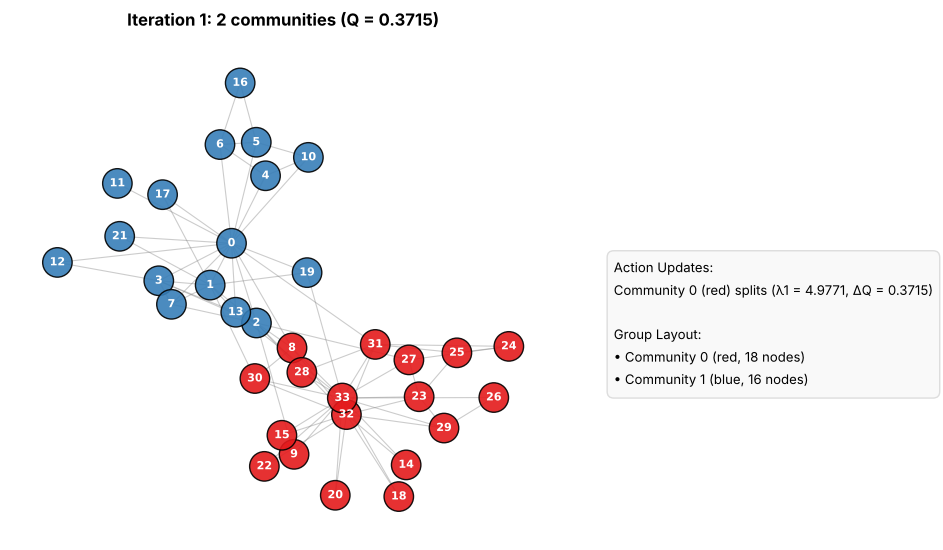

########## Iteration 2 ##########
Community 0 (red) splits (λ1 = 0.8594, ΔQ = 0.0207)
Community 1 (blue) splits (λ1 = 1.1785, ΔQ = 0.0012)
Modularity score Q = 0.3934


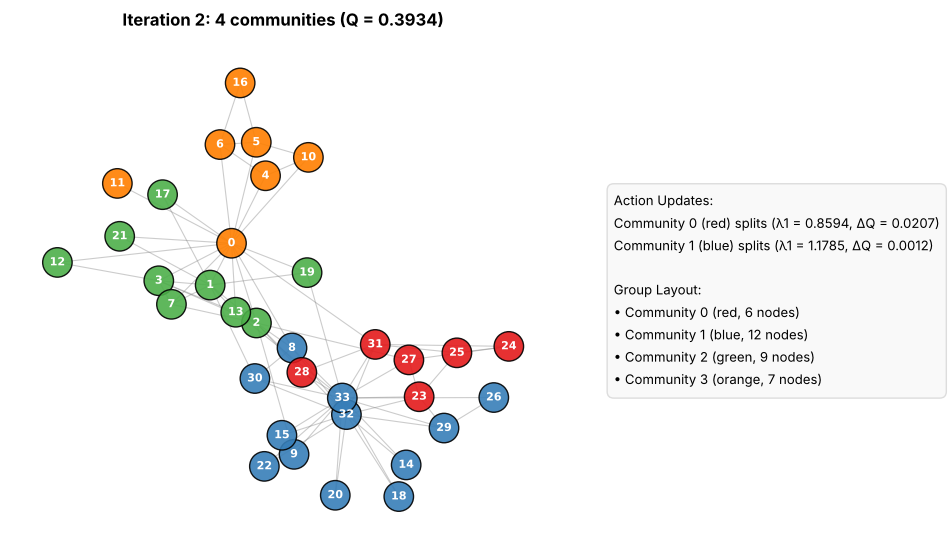

Global Pipeline Bisection Completed Successfully.


In [6]:
for iteration in range(1, 3):
    next_generation_communities = []
    logs_summary = []

    current_level_groups = list(communities)

    for c_idx, comm in enumerate(current_level_groups):
        sub_n = len(comm)
        if sub_n <= 1:
            next_generation_communities.append(comm)
            continue

        B_C = np.zeros((sub_n, sub_n))
        for idx_i, node_i in enumerate(comm):
            for idx_j, node_j in enumerate(comm):
                if node_i != node_j:
                    B_C[idx_i, idx_j] = B_global[node_i, node_j]
                else:
                    row_sum = sum(B_global[node_i, k] for k in comm)
                    B_C[idx_i, idx_j] = B_global[node_i, node_i] - row_sum

        eigenvalues, eigenvectors = la.eigh(B_C)
        lambda_1 = eigenvalues[-1]
        u_1 = eigenvectors[:, -1]

        if lambda_1 > 1e-10:
            s = np.where(u_1 >= 0, 1, -1)
            delta_Q = s @ B_C @ s / (2 * twom)

            if delta_Q > 1e-10 and abs(s.sum()) < len(s):
                c_plus = [node for node, si in zip(comm, s) if si > 0]
                c_minus = [node for node, si in zip(comm, s) if si < 0]
                next_generation_communities.append(c_plus)
                next_generation_communities.append(c_minus)

                c_name = color_names[c_idx % len(color_names)]
                logs_summary.append(
                    f"Community {c_idx} ({c_name}) splits (λ1 = {lambda_1:.4f}, ΔQ = {delta_Q:.4f})"
                )
                continue

        next_generation_communities.append(comm)

    communities = next_generation_communities
    compute_metrics(iteration)          # <-- store metrics after each split
    summary_notes = "\n".join(logs_summary) if logs_summary else "No valid splitting points found."
    render_iteration_snapshot(iteration, summary_notes)

print("Global Pipeline Bisection Completed Successfully.")

### Reading the output

| Iteration | What happened | Result |
|---|---|---|
| 0 | one group of 34 nodes | $Q=0$ |
| 1 | the whole graph splits ($\lambda_1=4.977$, $\Delta Q=0.3715$) | 2 communities, $Q=0.3715$ |
| 2 | both halves split again ($\Delta Q=0.0207$ and $0.0012$) | 4 communities, $Q=0.3934$ |

Two things stand out:

* **The first split does almost all the work.** It gives $Q=0.3715$ in one step. The second level adds only $0.022$, and the second split there ($\Delta Q=0.0012$) is a very small gain.
* **The loop is written for two iterations, and that is enough.** The loop runs `range(1, 3)`. Running the same procedure for more iterations produces **no further splits**: every remaining community is either non-splittable ($\lambda_1\le0$) or a split would not raise $Q$. So the 4-community result is a stable stopping point and not an arbitrary cut-off. If you want the code to stop on its own, replace `range(1, 3)` with a larger range such as `range(1, 10)`.

---
## 7. Preparing the evolution plots

Here we collect what the plots need:

* `iters` are the iteration numbers that have stored metrics, and `metric_names` are the four metric names.
* `final_color` gives each node the colour of the community it ends up in, so that a line in a plot can be traced back to its group.
* `legend_handles` builds a legend entry for every final community, showing its colour and size.

In [7]:
iters = sorted(metrics_history.keys())
metric_names = list(metrics_history[iters[0]].keys())
nodes = list(G.nodes())

# Color each node by its FINAL community so trends are easy to compare
final_color = {}
for c_idx, comm in enumerate(communities):
    for node in comm:
        final_color[node] = color_hex[c_idx % len(color_hex)]

legend_handles = [
    Line2D([0], [0], color=color_hex[i % len(color_hex)], lw=3,
           label=f"Final community {i} ({color_names[i % len(color_names)]}, {len(c)} nodes)")
    for i, c in enumerate(communities)
]

---
## 8. Evolution of the metrics

There is one panel per metric and **one line per node**, with the x-axis showing the iteration. Line colours show the node's *final* community, and the five nodes with the highest value at the last iteration are labelled with their IDs.

How to read it: a line that rises or falls steeply means the node's role changed when the communities were refined, while a flat line means the node's position is unaffected by the split.

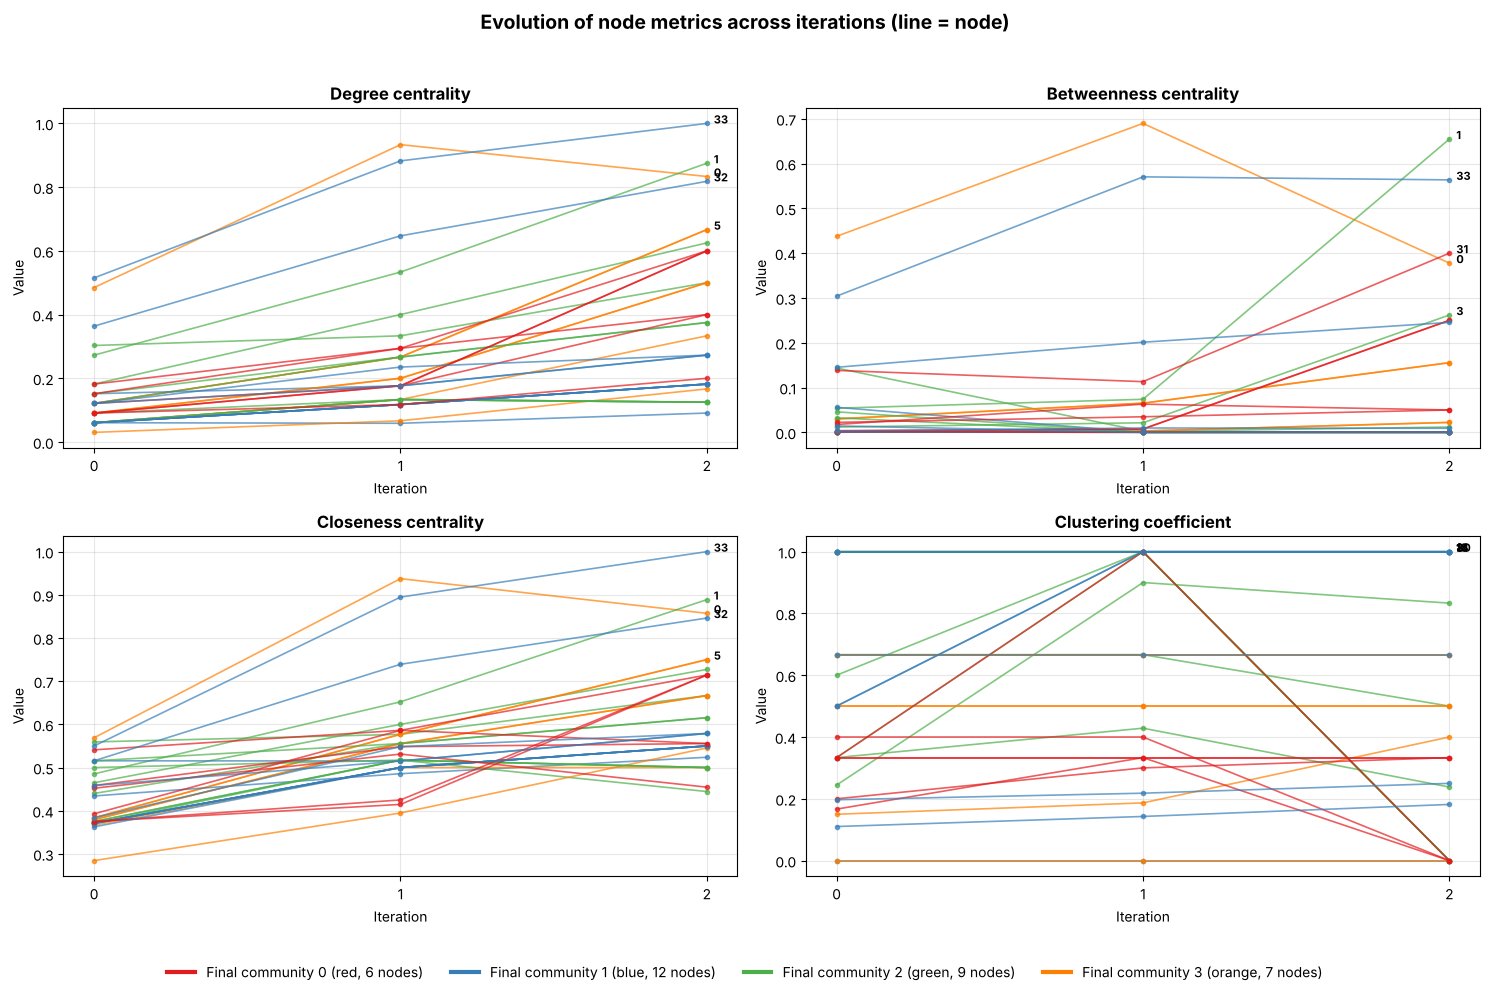

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, metric in zip(axes.ravel(), metric_names):
    for node in nodes:
        y = [metrics_history[it][metric][node] for it in iters]
        ax.plot(iters, y, marker='o', ms=3, lw=1.2, alpha=0.7, color=final_color[node])

    # Label the 5 highest nodes at the last iteration
    last = metrics_history[iters[-1]][metric]
    for node in sorted(last, key=last.get, reverse=True)[:5]:
        ax.annotate(str(node), (iters[-1], last[node]),
                    xytext=(5, 0), textcoords='offset points', fontsize=8, fontweight='bold')

    ax.set_title(metric, fontweight='bold')
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Value")
    ax.set_xticks(iters)
    ax.grid(alpha=0.3)

fig.legend(handles=legend_handles, loc='lower center', ncol=len(legend_handles), frameon=False)
fig.suptitle("Evolution of node metrics across iterations (line = node)", fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()

---
## 9. Top-5 nodes per metric and iteration

The plots show trends for all 34 nodes, but it is hard to read exact values from them. This cell prints, for each metric and each iteration, the **five highest-scoring nodes** with their values in brackets, so we can see precisely which nodes lead and how the leaders change after each split.

* `sorted(vals, key=vals.get, reverse=True)[:5]` sorts the nodes by their metric value from highest to lowest and keeps the first five.
* Iteration 0 is the whole graph, iteration 1 is after the first split (2 communities) and iteration 2 is after the second level (4 communities).

In [9]:
for metric in metric_names:
    print(f"\n=== Top 5 nodes by {metric} ===")
    for it in iters:
        vals = metrics_history[it][metric]
        top = sorted(vals, key=vals.get, reverse=True)[:5]
        print(f"Iteration {it}: " + ", ".join(f"{v} ({vals[v]:.3f})" for v in top))


=== Top 5 nodes by Degree centrality ===
Iteration 0: 33 (0.515), 0 (0.485), 32 (0.364), 2 (0.303), 1 (0.273)
Iteration 1: 0 (0.933), 33 (0.882), 32 (0.647), 1 (0.533), 3 (0.400)
Iteration 2: 33 (1.000), 1 (0.875), 0 (0.833), 32 (0.818), 5 (0.667)

=== Top 5 nodes by Betweenness centrality ===
Iteration 0: 0 (0.438), 33 (0.304), 32 (0.145), 2 (0.144), 31 (0.138)
Iteration 1: 0 (0.690), 33 (0.570), 32 (0.201), 31 (0.113), 1 (0.074)
Iteration 2: 1 (0.655), 33 (0.564), 31 (0.400), 0 (0.378), 3 (0.262)

=== Top 5 nodes by Closeness centrality ===
Iteration 0: 0 (0.569), 2 (0.559), 33 (0.550), 31 (0.541), 8 (0.516)
Iteration 1: 0 (0.938), 33 (0.895), 32 (0.739), 1 (0.652), 3 (0.600)
Iteration 2: 33 (1.000), 1 (0.889), 0 (0.857), 32 (0.846), 5 (0.750)

=== Top 5 nodes by Clustering coefficient ===
Iteration 0: 7 (1.000), 12 (1.000), 14 (1.000), 15 (1.000), 16 (1.000)
Iteration 1: 8 (1.000), 14 (1.000), 15 (1.000), 18 (1.000), 20 (1.000)
Iteration 2: 8 (1.000), 14 (1.000), 15 (1.000), 18 (1.

### The same output as tables

For easier reading, here are the printed results as tables (node ID, with the value in brackets).

**Degree centrality**

| Iteration | 1st | 2nd | 3rd | 4th | 5th |
|---|---|---|---|---|---|
| 0 | 33 (0.515) | 0 (0.485) | 32 (0.364) | 2 (0.303) | 1 (0.273) |
| 1 | 0 (0.933) | 33 (0.882) | 32 (0.647) | 1 (0.533) | 3 (0.400) |
| 2 | 33 (1.000) | 1 (0.875) | 0 (0.833) | 32 (0.818) | 5 (0.667) |

**Betweenness centrality**

| Iteration | 1st | 2nd | 3rd | 4th | 5th |
|---|---|---|---|---|---|
| 0 | 0 (0.438) | 33 (0.304) | 32 (0.145) | 2 (0.144) | 31 (0.138) |
| 1 | 0 (0.690) | 33 (0.570) | 32 (0.201) | 31 (0.113) | 1 (0.074) |
| 2 | 1 (0.655) | 33 (0.564) | 31 (0.400) | 0 (0.378) | 3 (0.262) |

**Closeness centrality**

| Iteration | 1st | 2nd | 3rd | 4th | 5th |
|---|---|---|---|---|---|
| 0 | 0 (0.569) | 2 (0.559) | 33 (0.550) | 31 (0.541) | 8 (0.516) |
| 1 | 0 (0.938) | 33 (0.895) | 32 (0.739) | 1 (0.652) | 3 (0.600) |
| 2 | 33 (1.000) | 1 (0.889) | 0 (0.857) | 32 (0.846) | 5 (0.750) |

**Clustering coefficient**

| Iteration | 1st | 2nd | 3rd | 4th | 5th |
|---|---|---|---|---|---|
| 0 | 7 (1.000) | 12 (1.000) | 14 (1.000) | 15 (1.000) | 16 (1.000) |
| 1 | 8 (1.000) | 14 (1.000) | 15 (1.000) | 18 (1.000) | 20 (1.000) |
| 2 | 8 (1.000) | 14 (1.000) | 15 (1.000) | 18 (1.000) | 20 (1.000) |

**How to read the tables**

* **Degree and closeness** give almost the same ranking, which is expected: a node with many direct links is also close to everyone else. The values jump between iterations because they are normalised by community size, so the useful comparison is *who is in the list*, not the absolute value.
* **Betweenness** is the most revealing. At iteration 0 the list contains node 2, which is a bridge between the two factions. After the splits node 2 disappears and node 1 takes the top place (0.655), because node 1 has become the main broker inside its own community once node 0 is in a different one.
* **Clustering** is full of ties. The number of nodes with a clustering coefficient of exactly 1.0 is 11, 16, 11 at iterations 0, 1 and 2, so the "top 5" is only the first five of a larger tied group. The node IDs shown for this metric should therefore not be read as a true ranking.

---
## 10. Discussion

### What the algorithm found

The method needs only the graph, yet it recovers the structure of the real split. After the first split ($Q=0.3715$) the two groups match the club's actual division apart from a single member, node 8. After the second level there are four communities with $Q=0.3934$, and each one belongs almost entirely to one real faction:

| Final community | Nodes | Real faction |
|---|---|---|
| 0 (red) | 23, 24, 25, 27, 28, 31 | all Officer's side |
| 1 (blue) | 8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33 | Officer's side, except node 8 |
| 2 (green) | 1, 2, 3, 7, 12, 13, 17, 19, 21 | all Mr. Hi's side |
| 3 (orange) | 0, 4, 5, 6, 10, 11, 16 | all Mr. Hi's side |

### Which nodes remain central across splits

Looking at the five highest nodes at iterations 0, 1 and 2:

* **Nodes 0 and 33 are the most consistent.** They are in the top five for degree, betweenness *and* closeness at every iteration. These are the two leaders of the real conflict (Mr. Hi and the club president), and each remains the dominant node of its own side however the groups are cut.
* **Node 32** (degree) and **node 31** (betweenness) are also present at every iteration, as strong local leaders one step below the two main hubs.
* **Node 1 changes its role.** Its betweenness rises from 0.054 to 0.655, which is the highest in the final iteration. Once node 0 sits in a different community, node 1 becomes the main broker of its 9-node group.
* **Node 2 loses its bridge role.** In the whole graph its betweenness is 0.144, because it links the two factions. Inside its own community it drops to 0.012, since it is then an ordinary member and not a connector.
* **Clustering follows a different pattern from the others.** The highest values belong to low-degree nodes whose few neighbours all know each other (for example 8, 14, 15, 18 and 20 reach exactly 1.0). Many nodes are tied at 1.0, so the *ordering* in the top five for this metric should not be over-interpreted.

### How community structure influences the metrics

1. **Degree and closeness rise as communities shrink.** Both are normalised by the community size, so the same neighbours become a larger fraction. For example, node 33 reaches degree and closeness 1.0 because it is linked to every other node in its community. These absolute values are therefore not comparable across iterations, and the meaningful comparison is the *ranking inside a community*.
2. **Betweenness separates hubs from bridges.** Cutting along a community boundary removes the inter-community edges that made bridge nodes (such as node 2) important, while nodes that organise a group from the inside keep or gain betweenness (such as nodes 33 and 1).
3. **Clustering reflects local density.** Within a community, edges are denser than in the full graph, so a node whose neighbours were split across both factions (node 2: 0.244 → 0.833) sees a large increase.
4. **The within-community view is partial.** Edges that leave a community are ignored when its metrics are computed, so these numbers describe a node's role *inside its group* and not its position in the whole network.

### Notes on the method

* **Generalised matrix.** This notebook uses Newman's generalised $\mathbf{B}^{(C)}$, which subtracts the row-sum correction on the diagonal. The handout's simpler restricted block (without this correction) only gives a sufficient stopping test, whereas the generalised version gives the exact $\Delta Q$ used in Step 5 above.
* **Dependencies.** This notebook imports `scipy` for `eigh`, so `scipy` must be installed in addition to NumPy, NetworkX and Matplotlib.

### Reference

Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103